In [101]:
import pandas as pd
%pip install datasets pandas scikit-learn matplotlib

In [102]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

df = dataset["train"].to_pandas()

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (26872, 5)


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [103]:
# Check the dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (26872, 5)

Column names:
['flags', 'instruction', 'category', 'intent', 'response']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26872 entries, 0 to 26871
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   flags        26872 non-null  object
 1   instruction  26872 non-null  object
 2   category     26872 non-null  object
 3   intent       26872 non-null  object
 4   response     26872 non-null  object
dtypes: object(5)
memory usage: 1.0+ MB

Missing values:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Duplicate rows: 0


In [104]:
# Count unique customer intents
print("Number of unique intents:", df["intent"].nunique())

# Count examples for each intent
intent_counts = df["intent"].value_counts()

print("\nExamples per intent:")
print(intent_counts)

Number of unique intents: 27

Examples per intent:
intent
contact_customer_service    1000
complaint                   1000
check_invoice               1000
switch_account              1000
edit_account                1000
contact_human_agent          999
check_payment_methods        999
delivery_period              999
newsletter_subscription      999
get_invoice                  999
payment_issue                999
registration_problems        999
cancel_order                 998
place_order                  998
track_refund                 998
change_order                 997
set_up_shipping_address      997
check_refund_policy          997
create_account               997
get_refund                   997
review                       997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64


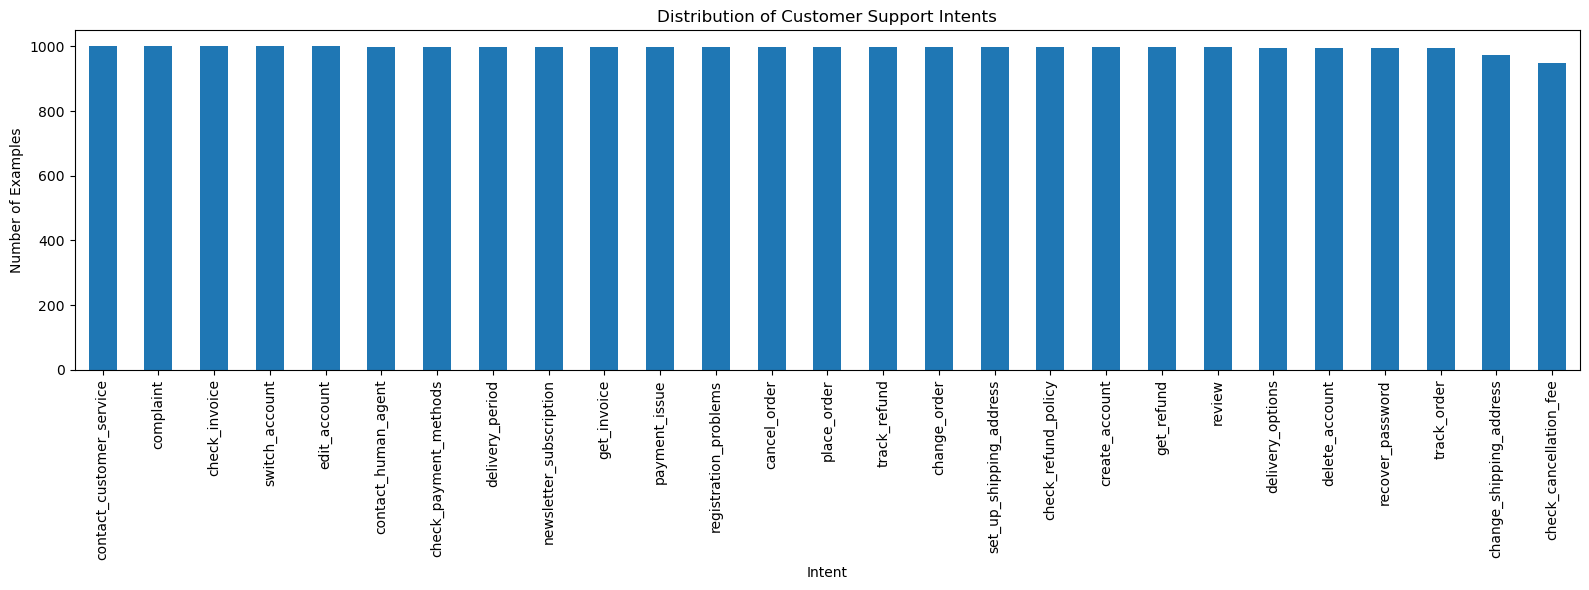

In [105]:
import matplotlib.pyplot as plt

intent_counts.plot(
    kind="bar",
    figsize=(16, 6)
)

plt.title("Distribution of Customer Support Intents")
plt.xlabel("Intent")
plt.ylabel("Number of Examples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [106]:
# Display 10 random customer messages
df[["instruction", "category", "intent"]].sample(
    10,
    random_state=42
)

,instruction,category,intent
9329,I can't talk with a human agent,CONTACT,contact_human_agent
4160,I have got to locate hte bills from {{Person N...,INVOICE,check_invoice
18500,"I cannot pay, help me to inform of a problem w...",PAYMENT,payment_issue
8840,I want help speaking to customer service,CONTACT,contact_customer_service
5098,I try to see th accepted payment options,PAYMENT,check_payment_methods
17250,where to sign up to the company nmewsletter,SUBSCRIPTION,newsletter_subscription
3589,I'd like to see the withdrwaal fee how can i d...,CANCEL,check_cancellation_fee
9043,I want to speak with someone,CONTACT,contact_human_agent
15800,can you help me getting bill #85632?,INVOICE,get_invoice
4384,I don't know how to take a quick look at invoi...,INVOICE,check_invoice


In [107]:
# Check whether customer messages are repeated
print("Total customer messages:", len(df))

print(
    "Unique customer messages:",
    df["instruction"].nunique()
)

print(
    "Repeated customer messages:",
    df["instruction"].duplicated().sum()
)

Total customer messages: 26872
Unique customer messages: 24635
Repeated customer messages: 2237


In [108]:
# Examine how broad categories map to individual intents
print("Number of categories:", df["category"].nunique())

print("\nNumber of intents per category:")
print(
    df.groupby("category")["intent"]
      .nunique()
      .sort_values(ascending=False)
)

print("\nCategory and intent examples:")
display(
    df[["instruction", "category", "intent"]].sample(
        10, random_state=42
    )
)

Number of categories: 11

Number of intents per category:
category
ACCOUNT         6
ORDER           4
REFUND          3
INVOICE         2
CONTACT         2
FEEDBACK        2
DELIVERY        2
SHIPPING        2
PAYMENT         2
CANCEL          1
SUBSCRIPTION    1
Name: intent, dtype: int64

Category and intent examples:


,instruction,category,intent
9329,I can't talk with a human agent,CONTACT,contact_human_agent
4160,I have got to locate hte bills from {{Person N...,INVOICE,check_invoice
18500,"I cannot pay, help me to inform of a problem w...",PAYMENT,payment_issue
8840,I want help speaking to customer service,CONTACT,contact_customer_service
5098,I try to see th accepted payment options,PAYMENT,check_payment_methods
17250,where to sign up to the company nmewsletter,SUBSCRIPTION,newsletter_subscription
3589,I'd like to see the withdrwaal fee how can i d...,CANCEL,check_cancellation_fee
9043,I want to speak with someone,CONTACT,contact_human_agent
15800,can you help me getting bill #85632?,INVOICE,get_invoice
4384,I don't know how to take a quick look at invoi...,INVOICE,check_invoice


In [109]:
print("Number of categories:", df["category"].nunique())

Number of categories: 11


In [110]:
df.groupby("category")

In [111]:
print("Total messages:", len(df))

print("Unique messages:", df["instruction"].nunique())
print(
    "Repeated messages:",
    df["instruction"].duplicated().sum()
)

Total messages: 26872
Unique messages: 24635
Repeated messages: 2237


In [112]:
# Group messages and count their distinct intent labels
intent_counts_per_message = (
    df.groupby("instruction")["intent"]
      .nunique()
)

# Find messages associated with more than one intent
conflicting_messages = intent_counts_per_message[
    intent_counts_per_message > 1
]

print(
    "Messages associated with multiple intents:",
    len(conflicting_messages)
)

Messages associated with multiple intents: 0


In [113]:
from sklearn.model_selection import GroupShuffleSplit

# Input feature and target
X = df["instruction"]
y = df["intent"]

# Use the original message as the group
groups = df["instruction"]

# Split the data while keeping identical messages together
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Display the results
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining proportion:",
      round(len(X_train) / len(df) * 100, 2), "%")

print("Testing proportion:",
      round(len(X_test) / len(df) * 100, 2), "%")



Training messages: 21466
Testing messages: 5406

Training proportion: 79.88 %
Testing proportion: 20.12 %


In [114]:
print("Unique intents in original dataset:", y.nunique())
print("Unique intents in training set:", y_train.nunique())
print("Unique intents in testing set:", y_test.nunique())

Unique intents in original dataset: 27
Unique intents in training set: 27
Unique intents in testing set: 27


In [115]:
# Count examples of each intent in the training set
train_intent_counts = y_train.value_counts()

print("Training set intent distribution:")
print(train_intent_counts)

Training set intent distribution:
intent
review                      829
delete_account              822
newsletter_subscription     816
change_order                813
get_refund                  806
complaint                   806
place_order                 805
recover_password            803
get_invoice                 801
check_invoice               801
check_refund_policy         800
track_order                 793
registration_problems       793
delivery_period             792
set_up_shipping_address     792
contact_human_agent         792
delivery_options            792
create_account              790
switch_account              787
contact_customer_service    784
edit_account                784
payment_issue               784
check_payment_methods       783
change_shipping_address     782
track_refund                778
cancel_order                770
check_cancellation_fee      768
Name: count, dtype: int64


In [116]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf =TfidfVectorizer(
    lowercase = True,
    stop_words = 'english',
    ngram_range =(1,2),
    max_features = 10000
)

In [117]:
# Learn the vocabulary and calculate TF-IDF features from training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

In [118]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (21466, 10000)
Testing TF-IDF shape: (5406, 10000)
Number of TF-IDF features: 10000


In [119]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)
model.fit(X_train_tfidf,y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [120]:
y_pred = model.predict(X_test_tfidf)

In [121]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 0.9756
Model Accuracy: 97.56%


In [122]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print(report)

                          precision    recall  f1-score   support

            cancel_order       1.00      0.96      0.98       228
            change_order       0.91      0.98      0.95       184
 change_shipping_address       0.99      0.98      0.99       191
  check_cancellation_fee       1.00      1.00      1.00       182
           check_invoice       0.85      0.85      0.85       199
   check_payment_methods       1.00      0.98      0.99       216
     check_refund_policy       0.98      0.99      0.99       197
               complaint       0.99      1.00      1.00       194
contact_customer_service       1.00      1.00      1.00       216
     contact_human_agent       1.00      0.99      1.00       207
          create_account       1.00      0.95      0.98       207
          delete_account       0.91      0.99      0.95       173
        delivery_options       1.00      1.00      1.00       203
         delivery_period       1.00      1.00      1.00       207
         

In [123]:
# Create a DataFrame containing the actual and predicted intents
results_df = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual_intent": y_test.to_numpy(),
    "predicted_intent": y_pred
})

# Keep only incorrectly classified messages
errors_df = results_df[
    results_df["actual_intent"] != results_df["predicted_intent"]
]

# Display the total number of errors
print("Total incorrect predictions:", len(errors_df))

# Display the first 20 errors
print(errors_df.head(20).to_string(index=False))

Total incorrect predictions: 132
                                                     message           actual_intent predicted_intent
             can uhelp me cancelliung order {{Order Number}}            cancel_order     change_order
     I don't know how I can camcel purchase {{Order Number}}            cancel_order     change_order
              could uhelp me cancelin order {{Order Number}}            cancel_order     change_order
         i need help with cancelliung order {{Order Number}}            cancel_order     change_order
                                           order cancelation            cancel_order      place_order
             can uhelp me cancelliung order {{Order Number}}            cancel_order     change_order
         question about cancellung purchase {{Order Number}}            cancel_order     change_order
            need help with cfanceling order {{Order Number}}            cancel_order     change_order
                              update purchase1135

In [124]:
from sklearn.metrics import confusion_matrix
import pandas as pd

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

# Convert it into a readable DataFrame
cm_df = pd.DataFrame(
    cm,
    index=model.classes_,
    columns=model.classes_
)

# Remove correct predictions from consideration
import numpy as np

np.fill_diagonal(cm, 0)

# Find the five most frequent types of misclassification
confusion_pairs = (
    pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
    .stack()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 confusion pairs:")
print(confusion_pairs)

Top 5 confusion pairs:
check_invoice   get_invoice       30
get_invoice     check_invoice     29
create_account  delete_account     9
track_order     change_order       8
cancel_order    change_order       7
dtype: int64


In [125]:
# Find invoice-related classification errors
invoice_errors = errors_df[
    (
        (errors_df["actual_intent"] == "check_invoice") &
        (errors_df["predicted_intent"] == "get_invoice")
    ) |
    (
        (errors_df["actual_intent"] == "get_invoice") &
        (errors_df["predicted_intent"] == "check_invoice")
    )
]

# Display the messages
print("Total invoice-related errors:", len(invoice_errors))

print(
    invoice_errors[
        ["message", "actual_intent", "predicted_intent"]
    ].head(15).to_string(index=False)
)

Total invoice-related errors: 59
                                                          message actual_intent predicted_intent
                                                  find bil #12588 check_invoice      get_invoice
      need help lpocating the bloody invoice from {{Person Name}} check_invoice      get_invoice
                                  see invoicefrom {{Person Name}} check_invoice      get_invoice
         I want to find my bill from {{Person Name}}, I need help check_invoice      get_invoice
                                               see invoice #37777 check_invoice      get_invoice
                 I don't know what to do to see my invoice #00108 check_invoice      get_invoice
I need to see the invoices from {{Person Name}}, can you help me? check_invoice      get_invoice
         I want assistance to see my invoice from {{Person Name}} check_invoice      get_invoice
                   what do i need to do to find my invoice #12588 check_invoice      get_invoi

In [126]:
# Display 10 examples of each intent

print("========== CHECK INVOICE ==========")

print(
    df[df["intent"] == "check_invoice"]["instruction"]
    .head(10)
    .to_string(index=False)
)

print("\n========== GET INVOICE ==========")

print(
    df[df["intent"] == "get_invoice"]["instruction"]
    .head(10)
    .to_string(index=False)
)

========== CHECK INVOICE ==========
                 show me invoice{{Invoice Number}}
       need to see my invoicesfrom {{Person Name}}
I have to see my invoice from {{Person Name}}, ...
can you help me seeing the invoice from {{Perso...
              how can I locate the invoice #37777?
I need to look for the fucking invoices from {{...
i need assistance giving a quick look at the bv...
                can you help me check bill #12588?
                            locate the bill #12588
want assistance giving a quick look at the bill...

========== GET INVOICE ==========
i dont know what i need to do to download my bi...
        want assistance to download invoice #85632
what do I need to do to get my bill from {{Pers...
I don't know what I need to do to get the bill ...
need help getting the invoices from {{Person Na...
                                get invoice #37777
what do I need to do to download my bill from {...
         i lost bill #12588 could ya mail it to me
where do i 

In [127]:
import pandas as pd

# Get all words and phrases learned by TF-IDF
feature_names = tfidf.get_feature_names_out()

# Get the class labels learned by Logistic Regression
classes = model.classes_

# Find the positions of the two invoice intents
check_idx = list(classes).index("check_invoice")
get_idx = list(classes).index("get_invoice")

# Get the model's learned coefficients for both intents
check_weights = model.coef_[check_idx]
get_weights = model.coef_[get_idx]

# Display the strongest features for each intent
check_df = pd.DataFrame({
    "word_or_phrase": feature_names,
    "weight": check_weights
}).sort_values("weight", ascending=False)

get_df = pd.DataFrame({
    "word_or_phrase": feature_names,
    "weight": get_weights
}).sort_values("weight", ascending=False)

print("Top features for CHECK_INVOICE:")
print(check_df.head(15).to_string(index=False))

print("\nTop features for GET_INVOICE:")
print(get_df.head(15).to_string(index=False))

Top features for CHECK_INVOICE:
word_or_phrase   weight
        person 8.076955
          look 5.772963
         37777 5.387631
         00108 5.039601
         12588 4.773689
         85632 4.662892
       invoice 4.482329
        locate 4.446385
         check 3.350153
      invoices 3.291934
         quick 2.685037
    quick look 2.255483
  bills person 2.195050
         bills 2.183458
      checking 2.178206

Top features for GET_INVOICE:
word_or_phrase   weight
        person 7.794220
      download 6.114256
       invoice 5.060260
         85632 4.829374
         12588 4.624348
         00108 4.567543
         37777 4.431278
       getting 3.695642
          mail 3.436709
   downloading 3.342928
      invoices 3.085435
         bills 2.335301
          send 2.240005
          know 2.012492
  bills person 1.775369


In [128]:
# Create new customer messages
new_messages = [
    "I need to check whether my invoice is correct.",
    "Please download my invoice for me.",
    "Can you tell me where I can view my bill?",
    "Please email me a copy of my invoice.",
    "I want to inspect the charges on my bill.",
    "I cannot find the option to download my receipt.",
    "Could you send invoice number 987654 to my email?",
    "I want to see my invoice but not download it."
]

# Convert the messages into TF-IDF features
new_messages_tfidf = tfidf.transform(new_messages)

# Predict the intent of each message
new_predictions = model.predict(new_messages_tfidf)

# Display the results
for message, prediction in zip(new_messages, new_predictions):
    print(f"Message: {message}")
    print(f"Predicted intent: {prediction}")
    print("-" * 60)

Message: I need to check whether my invoice is correct.
Predicted intent: check_invoice
------------------------------------------------------------
Message: Please download my invoice for me.
Predicted intent: get_invoice
------------------------------------------------------------
Message: Can you tell me where I can view my bill?
Predicted intent: change_shipping_address
------------------------------------------------------------
Message: Please email me a copy of my invoice.
Predicted intent: get_invoice
------------------------------------------------------------
Message: I want to inspect the charges on my bill.
Predicted intent: check_cancellation_fee
------------------------------------------------------------
Message: I cannot find the option to download my receipt.
Predicted intent: get_invoice
------------------------------------------------------------
Message: Could you send invoice number 987654 to my email?
Predicted intent: get_invoice
---------------------------------

In [129]:
import pandas as pd

# Get the predicted probability for every intent
prediction_probabilities = model.predict_proba(new_messages_tfidf)

# Get the intent names
intent_names = model.classes_

# Display the three highest-probability intents for each message
for message, probabilities in zip(new_messages, prediction_probabilities):

    # Find the positions of the three highest probabilities
    top_indices = probabilities.argsort()[-3:][::-1]

    print(f"\nMessage: {message}")
    print("Top 3 predicted intents:")

    for index in top_indices:
        print(
            f"{intent_names[index]}: "
            f"{probabilities[index]:.2%}"
        )

    print("-" * 50)


Message: I need to check whether my invoice is correct.
Top 3 predicted intents:
check_invoice: 71.16%
check_refund_policy: 2.98%
change_shipping_address: 2.53%
--------------------------------------------------

Message: Please download my invoice for me.
Top 3 predicted intents:
get_invoice: 98.68%
check_invoice: 0.18%
place_order: 0.07%
--------------------------------------------------

Message: Can you tell me where I can view my bill?
Top 3 predicted intents:
change_shipping_address: 12.83%
newsletter_subscription: 8.58%
place_order: 4.97%
--------------------------------------------------

Message: Please email me a copy of my invoice.
Top 3 predicted intents:
get_invoice: 63.39%
check_invoice: 31.74%
place_order: 0.27%
--------------------------------------------------

Message: I want to inspect the charges on my bill.
Top 3 predicted intents:
check_cancellation_fee: 67.34%
check_refund_policy: 3.95%
place_order: 2.21%
--------------------------------------------------

Messa

In [130]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the Linear SVM model
svm_model = LinearSVC(random_state=42)

# Train it on the training data
svm_model.fit(X_train_tfidf, y_train)

# Predict intents for the test data
svm_predictions = svm_model.predict(X_test_tfidf)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

print(f"Linear SVM Accuracy: {svm_accuracy:.4f}")
print(f"Linear SVM Accuracy: {svm_accuracy * 100:.2f}%")

Linear SVM Accuracy: 0.9785
Linear SVM Accuracy: 97.85%


In [131]:
from sklearn.metrics import classification_report

# Generate a detailed evaluation report
svm_report = classification_report(
    y_test,
    svm_predictions,
    digits=4
)

print(svm_report)

                          precision    recall  f1-score   support

            cancel_order     0.9865    0.9649    0.9756       228
            change_order     0.9293    1.0000    0.9634       184
 change_shipping_address     0.9894    0.9791    0.9842       191
  check_cancellation_fee     1.0000    1.0000    1.0000       182
           check_invoice     0.8534    0.8191    0.8359       199
   check_payment_methods     1.0000    0.9769    0.9883       216
     check_refund_policy     0.9948    0.9797    0.9872       197
               complaint     0.9949    1.0000    0.9974       194
contact_customer_service     0.9954    1.0000    0.9977       216
     contact_human_agent     1.0000    1.0000    1.0000       207
          create_account     0.9951    0.9807    0.9878       207
          delete_account     0.9719    1.0000    0.9858       173
        delivery_options     0.9951    1.0000    0.9975       203
         delivery_period     0.9952    0.9952    0.9952       207
         

In [132]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a vectorizer that learns character patterns
char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=20000
)

print("Character-level TF-IDF vectorizer created.")

Character-level TF-IDF vectorizer created.


In [133]:
# Learn character patterns from training messages
X_train_char = char_tfidf.fit_transform(X_train)

# Apply the learned patterns to test messages
X_test_char = char_tfidf.transform(X_test)

# Display the shapes
print("Training character TF-IDF shape:", X_train_char.shape)
print("Testing character TF-IDF shape:", X_test_char.shape)

print(
    "Number of character features:",
    len(char_tfidf.get_feature_names_out())
)

Training character TF-IDF shape: (21466, 18149)
Testing character TF-IDF shape: (5406, 18149)
Number of character features: 18149


In [134]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the character-based SVM model
char_svm_model = LinearSVC(random_state=42)

# Train the model
char_svm_model.fit(X_train_char, y_train)

# Predict intents for the test messages
char_svm_predictions = char_svm_model.predict(X_test_char)

# Calculate accuracy
char_svm_accuracy = accuracy_score(y_test, char_svm_predictions)

print(f"Character SVM Accuracy: {char_svm_accuracy:.4f}")
print(f"Character SVM Accuracy: {char_svm_accuracy * 100:.2f}%")

Character SVM Accuracy: 0.9987
Character SVM Accuracy: 99.87%


In [135]:
from sklearn.metrics import classification_report

# Evaluate character-level SVM for every intent
char_svm_report = classification_report(
    y_test,
    char_svm_predictions,
    digits=4
)

print(char_svm_report)

                          precision    recall  f1-score   support

            cancel_order     0.9956    1.0000    0.9978       228
            change_order     1.0000    1.0000    1.0000       184
 change_shipping_address     0.9948    1.0000    0.9974       191
  check_cancellation_fee     1.0000    1.0000    1.0000       182
           check_invoice     0.9900    1.0000    0.9950       199
   check_payment_methods     1.0000    0.9907    0.9953       216
     check_refund_policy     1.0000    1.0000    1.0000       197
               complaint     1.0000    1.0000    1.0000       194
contact_customer_service     1.0000    1.0000    1.0000       216
     contact_human_agent     1.0000    1.0000    1.0000       207
          create_account     0.9952    1.0000    0.9976       207
          delete_account     1.0000    1.0000    1.0000       173
        delivery_options     1.0000    1.0000    1.0000       203
         delivery_period     0.9952    1.0000    0.9976       207
         

In [136]:
# Create a DataFrame of actual and predicted intents
char_results_df = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual_intent": y_test.to_numpy(),
    "predicted_intent": char_svm_predictions
})

# Select incorrect predictions
char_errors_df = char_results_df[
    char_results_df["actual_intent"] !=
    char_results_df["predicted_intent"]
]

# Display the errors
print("Total incorrect predictions:", len(char_errors_df))

print(
    char_errors_df.to_string(index=False)
)

Total incorrect predictions: 7
                                                  message           actual_intent        predicted_intent
                                   can I pay with PayPal?   check_payment_methods           payment_issue
                                      can i pay witj visa   check_payment_methods            cancel_order
i need assistance to egt the invoice from {{Person Name}}             get_invoice           check_invoice
   I do not know what I need to do to egt the bill #85632             get_invoice           check_invoice
                                       help creating user   registration_problems          create_account
                                   shipping address issue set_up_shipping_address change_shipping_address
               when will purchase {{Order Number}} arrive             track_order         delivery_period


In [140]:
import pandas as pd

test_messages = [
    "hey, where's my package? it's taking forever",
    "I ordered something last week and it still hasn't arrived",
    "pls cancel my order, I changed my mind",
    "can u update the delivery address for my order?",
    "I entered the wrong shipping address. How can I fix it?",
    "I forgot my password and can't log in",
    "how do I get back into my account?",
    "I was charged twice for the same purchase",
    "my payment keeps getting declined",
    "which payment options do you accept?",
    "can you send the bill to my email?",
    "I need to download a copy of my receipt",
    "I want to check the charges on my invoice",
    "where can I see the status of my refund?",
    "it's been two weeks and my money hasn't come back",
    "I want to close my account permanently",
    "how do I sign up for an account?",
    "I want to speak to a real person, not a bot",
    "your service is terrible and I want to complain",
    "I don't want to receive promotional emails anymore",
    "my parcel hasn't arrived yet, can you help?",
    "I want to see my invoice but I don't want to download it",
    "i need help with my shippng adress",
    "can i pay using paypall?",
    "I ordered yesterday. When should it arrive?",
    "the website won't let me register",
    "please change the email linked to my account",
    "how much will I be charged if I cancel my order?"
]

generalization_df = pd.DataFrame({
    "message": test_messages
})

generalization_df.head()


,message
0,"hey, where's my package? it's taking forever"
1,I ordered something last week and it still has...
2,"pls cancel my order, I changed my mind"
3,can u update the delivery address for my order?
4,I entered the wrong shipping address. How can ...


In [142]:

# Convert the new customer messages into character-level TF-IDF features
X_generalization = char_tfidf.transform(generalization_df["message"])

# Predict the intent of each message
generalization_predictions = char_svm_model.predict(X_generalization)

# Store the predictions alongside the original messages
generalization_df["predicted_intent"] = generalization_predictions

# Display all predictions
print(generalization_df.to_string(index=False))



                                                  message        predicted_intent
             hey, where's my package? it's taking forever         delivery_period
I ordered something last week and it still hasn't arrived         delivery_period
                   pls cancel my order, I changed my mind            cancel_order
          can u update the delivery address for my order? change_shipping_address
  I entered the wrong shipping address. How can I fix it? change_shipping_address
                    I forgot my password and can't log in        recover_password
                       how do I get back into my account?             get_invoice
                I was charged twice for the same purchase  check_cancellation_fee
                        my payment keeps getting declined           payment_issue
                     which payment options do you accept?   check_payment_methods
                       can you send the bill to my email?             get_invoice
                

In [144]:

expected_intents = [
    "track_order",                 # 1
    "delivery_period",             # 2
    "cancel_order",                # 3
    "change_shipping_address",     # 4
    "change_shipping_address",     # 5
    "recover_password",            # 6
    "recover_password",            # 7
    "payment_issue",               # 8
    "payment_issue",               # 9
    "check_payment_methods",       # 10
    "get_invoice",                 # 11
    "get_invoice",                 # 12
    "check_invoice",               # 13
    "track_refund",                # 14
    "track_refund",                # 15
    "delete_account",              # 16
    "create_account",              # 17
    "contact_human_agent",         # 18
    "complaint",                   # 19
    "newsletter_subscription",     # 20
    "track_order",                 # 21
    "check_invoice",               # 22
    "change_shipping_address",     # 23
    "check_payment_methods",       # 24
    "delivery_period",             # 25
    "registration_problems",       # 26
    "edit_account",                # 27
    "check_cancellation_fee"       # 28
]

generalization_df["expected_intent"] = expected_intents

generalization_df["correct"] = (
    generalization_df["predicted_intent"]
    == generalization_df["expected_intent"]
)

print(generalization_df[
    ["message", "expected_intent", "predicted_intent", "correct"]
].to_string(index=False))

print("\nCorrect predictions:", generalization_df["correct"].sum())
print("Total messages:", len(generalization_df))
print(
    "Generalization accuracy:",
    round(generalization_df["correct"].mean() * 100, 2),
    "%"
)



                                                  message         expected_intent        predicted_intent  correct
             hey, where's my package? it's taking forever             track_order         delivery_period    False
I ordered something last week and it still hasn't arrived         delivery_period         delivery_period     True
                   pls cancel my order, I changed my mind            cancel_order            cancel_order     True
          can u update the delivery address for my order? change_shipping_address change_shipping_address     True
  I entered the wrong shipping address. How can I fix it? change_shipping_address change_shipping_address     True
                    I forgot my password and can't log in        recover_password        recover_password     True
                       how do I get back into my account?        recover_password             get_invoice    False
                I was charged twice for the same purchase           payment_issu

In [145]:

from scipy.sparse import hstack

# Combine word-level and character-level features
X_train_combined = hstack([
    X_train_tfidf,
    X_train_char
])

X_test_combined = hstack([
    X_test_tfidf,
    X_test_char
])

# Check the resulting shapes
print("Combined training shape:", X_train_combined.shape)
print("Combined testing shape:", X_test_combined.shape)


Combined training shape: (21466, 28149)
Combined testing shape: (5406, 28149)


In [147]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create the model
combined_svm_model = LinearSVC(random_state=42)

# Train it using the combined features
combined_svm_model.fit(X_train_combined, y_train)

# Predict intents for the test dataset
combined_predictions = combined_svm_model.predict(X_test_combined)

# Calculate accuracy
combined_accuracy = accuracy_score(y_test, combined_predictions)

print(f"Combined Model Accuracy: {combined_accuracy * 100:.2f}%")



Combined Model Accuracy: 99.80%


In [148]:

# Convert the new messages using the existing word and character vectorizers
X_new_word = tfidf.transform(generalization_df["message"])
X_new_char = char_tfidf.transform(generalization_df["message"])

# Combine both feature sets
X_new_combined = hstack([X_new_word, X_new_char])

# Predict the intents
combined_generalization_predictions = combined_svm_model.predict(
    X_new_combined
)

# Store the predictions
generalization_df["combined_prediction"] = (
    combined_generalization_predictions
)

# Check whether each prediction is correct
generalization_df["combined_correct"] = (
    generalization_df["combined_prediction"]
    == generalization_df["expected_intent"]
)

# Display the results
print(
    generalization_df[
        ["message", "expected_intent", "combined_prediction",
         "combined_correct"]
    ].to_string(index=False)
)

# Calculate accuracy
combined_generalization_accuracy = (
    generalization_df["combined_correct"].mean() * 100
)

print("\nCombined model generalization accuracy:",
      round(combined_generalization_accuracy, 2), "%")



                                                  message         expected_intent     combined_prediction  combined_correct
             hey, where's my package? it's taking forever             track_order         delivery_period             False
I ordered something last week and it still hasn't arrived         delivery_period             track_order             False
                   pls cancel my order, I changed my mind            cancel_order            cancel_order              True
          can u update the delivery address for my order? change_shipping_address change_shipping_address              True
  I entered the wrong shipping address. How can I fix it? change_shipping_address change_shipping_address              True
                    I forgot my password and can't log in        recover_password        recover_password              True
                       how do I get back into my account?        recover_password             get_invoice             False
        

In [149]:
import joblib
import os

# Create a folder to store the trained model files
os.makedirs("saved_models", exist_ok=True)

# Save the character-level TF-IDF vectorizer
joblib.dump(
    char_tfidf,
    "saved_models/char_tfidf_vectorizer.pkl"
)

# Save the trained character-level SVM model
joblib.dump(
    char_svm_model,
    "saved_models/char_svm_model.pkl"
)

print("Model and vectorizer saved successfully!")


Model and vectorizer saved successfully!


In [150]:

import joblib

# Load the saved vectorizer and model
loaded_vectorizer = joblib.load(
    "saved_models/char_tfidf_vectorizer.pkl"
)

loaded_model = joblib.load(
    "saved_models/char_svm_model.pkl"
)

# Enter a new customer message
customer_message = [
    "I want to track my order because it has not arrived"
]

# Convert the message into numerical features
message_features = loaded_vectorizer.transform(customer_message)

# Predict the customer's intent
predicted_intent = loaded_model.predict(message_features)

print("Customer message:", customer_message[0])
print("Predicted intent:", predicted_intent[0])




Customer message: I want to track my order because it has not arrived
Predicted intent: delivery_period


In [151]:
import os

print("Notebook working directory:")
print(os.getcwd())

print("\nSaved model files:")
print(os.listdir("saved_models"))

Notebook working directory:
C:\Users\ybamb

Saved model files:
['char_svm_model.pkl', 'char_tfidf_vectorizer.pkl']
